# 01 · Khám phá dữ liệu (EDA)

**Bài tập lớn ME3297 · Năng suất nhà máy may (UCI ID 597).**
Notebook này mô tả dữ liệu theo yêu cầu của đề (mô tả dữ liệu): số dòng/cột, từ điển dữ liệu, giá trị thiếu, ngoại lai, phân bố nhãn.
Mọi bảng/hình đều được sinh bằng hàm trong `src/` (cùng hàm mà `src/run_all.py` dùng để ghi vào `outputs/`).

> Trước khi chạy: đã có `data/garments_worker_productivity.csv` (xem README, bước `python src/get_data.py`).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # chạy được từ notebooks/ hoặc từ gốc repo
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", category=FutureWarning)

from config import DATA_FILE, SEED
import plots as P

import eda
from features import load_raw, build_dataset
from splits import split_train_test, TEST_START

## 1. Đọc dữ liệu thô
Giữ nguyên mọi giá trị (kể cả nhãn lỗi) để thấy đúng vấn đề chất lượng.

In [2]:
raw = load_raw(DATA_FILE)
print("Số dòng x số cột:", raw.shape)
raw.head()

Số dòng x số cột: (1197, 15)


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


**Nhận xét (dữ liệu thô).**
- 1.197 dòng × 15 cột. Mỗi dòng là một **tổ-ngày của một bộ phận** (tổ × bộ phận × ngày), không phải từng công nhân. Đơn vị dự báo cũng là tổ-ngày.
- Ngay 5 dòng đầu đã thấy hai vấn đề chất lượng: nhãn `sweing` viết sai chính tả và `wip = NaN` ở dòng finishing.
- Dòng 2 và 3 (tổ 11 và 12) trùng nhau ở mọi cột trừ `team`. Toàn bộ dữ liệu có 17 dòng rơi vào trường hợp này: cùng ngày, cùng bộ phận, khác tổ nhưng trùng hết các cột số, kể cả `actual_productivity` tới 6 chữ số. Có thể các tổ cùng làm một mã hàng và được ghi gộp, hoặc là lỗi sao chép khi nhập liệu. Bài giữ nguyên các dòng này; nên nêu trong phần giới hạn.

## 2. Làm sạch xác định và tạo nhãn
`build_dataset` làm sạch nhãn `department` (sửa `sweing` thành `sewing`, bỏ khoảng trắng thừa), đổi kiểu ngày, sắp xếp, tạo nhãn `miss`, `week_of_month` (thay cho `quarter`) và các đặc trưng lịch sử theo tổ-bộ phận (đặc trưng trễ).
Các bước này **không học tham số từ dữ liệu**. Hàm cũng chạy các `assert` chống rò rỉ cho đặc trưng trễ.

In [3]:
df = build_dataset(DATA_FILE)
train, test = split_train_test(df)
print("Train:", train.shape, "| Test:", test.shape)
df.head(3)

Train: (943, 24) | Test: (254, 24)


,row_id,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity,gap,miss,week_of_month,lag1_miss,lag1_gap,roll5_gap_mean,roll5_miss_rate,is_first_obs
0,0,2015-01-01,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500,0.136500,0,1,NaN,NaN,NaN,NaN,1
1,1,2015-01-01,Quarter1,sewing,Thursday,1,0.75,28.08,681.0,6900,45,0.0,0,0,57.5,0.750428,0.000428,0,1,NaN,NaN,NaN,NaN,1
2,2,2015-01-01,Quarter1,finishing,Thursday,2,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.755167,0.005167,0,1,NaN,NaN,NaN,NaN,1


**Nhận xét (sau làm sạch).**
- Từ 15 lên 24 cột: thêm `row_id`, `gap`, `miss`, `week_of_month` và 5 cột lịch sử (`lag1_miss`, `lag1_gap`, `roll5_gap_mean`, `roll5_miss_rate`, `is_first_obs`).
- Train 943 dòng (47 ngày), test 254 dòng (12 ngày), khoảng 79/21 theo số dòng. Tách theo **ngày**, nên không ngày nào nằm ở cả hai tập.
- Ba dòng đầu có đặc trưng trễ = NaN và `is_first_obs = 1` vì đó là ngày đầu tiên của mỗi cặp (tổ, bộ phận): chưa có lịch sử thì để trống, sau đó Pipeline điền trung vị (học trên train) và cờ báo cho mô hình biết.
- `actual_productivity` và `gap` là kết quả cuối ngày: chỉ dùng để tạo nhãn và đặc trưng trễ, không đưa trực tiếp vào mô hình.

## 3. Từ điển dữ liệu
Gồm cả các cột gốc và cột tạo thêm; cột `biet_dau_ca` là cơ sở để phân loại rò rỉ (quyết định ra lúc đầu ca nên chỉ dùng thông tin biết lúc đó).

In [4]:
eda.data_dictionary(df)

,cot,y_nghia,don_vi,biet_dau_ca,su_dung,kieu,n_thieu,pct_thieu,n_khac_nhau,min,trung_vi,max
0,date,Ngày ghi nhận (định dạng M/D/YYYY),ngày,Có,"Dùng để tạo week_of_month, đặc trưng trễ và tách train/test",ngày,0,0.00,59,2015-01-01 00:00:00,,2015-03-11 00:00:00
1,quarter,Tuần trong tháng do nguồn đặt tên 'Quarter1-5' (không phải quý),nhãn,Có,Không dùng; thay bằng week_of_month (tạo lại từ date),phân loại,0,0.00,5,,,
2,department,Bộ phận: sewing (may) hoặc finishing (hoàn thiện),nhãn,Có,"A, B (one-hot); làm sạch nhãn lỗi (sweing -> sewing, bỏ khoảng trắng thừa)",phân loại,0,0.00,2,,,
3,day,Thứ trong tuần,nhãn,Có,"A, B (one-hot)",phân loại,0,0.00,6,,,
4,team,"Mã tổ 1-12 (biến phân loại, không phải thứ tự)",mã,Có,"A, B (one-hot)",số,0,0.00,12,1,6.0,12
5,targeted_productivity,Năng suất mục tiêu (định mức) do quản lý đặt cho tổ trong ngày,tỷ lệ 0-1,Có,"A, B",số,0,0.00,9,0.07,0.75,0.8
6,smv,Standard Minute Value: thời gian chuẩn để làm một sản phẩm của mã hàng,phút/sản phẩm,Có,"A, B",số,0,0.00,70,2.9,15.26,54.56
7,wip,Work in progress: số sản phẩm dở dang (chỉ ghi nhận cho sewing),sản phẩm,Có (chỉ sewing),"A, B (điền 0 cho finishing, log1p, chuẩn hoá)",số,506,42.27,548,7.0,1039.0,23122.0
8,over_time,Tổng số phút tăng ca của tổ,phút,Không chắc,Chỉ kịch bản B (độ nhạy),số,0,0.00,143,0,3960.0,25920
9,incentive,Tiền thưởng tài chính cho tổ,BDT,Không chắc (có thể trả theo kết quả),Chỉ kịch bản B (độ nhạy); rủi ro rò rỉ chính,số,0,0.00,48,0,0.0,3600


**Nhận xét (từ điển dữ liệu).**
- Cột `biet_dau_ca` là tiêu chí chọn biến: quyết định ra lúc khoảng 7h, nên chỉ dùng thông tin đã biết lúc đó. Có bốn nhóm:

| Nhóm | Biến | Dùng ở |
|---|---|---|
| Biết chắc đầu ca | `department`, `day`, `team`, `targeted_productivity`, `smv`, `no_of_workers`, `wip`, `week_of_month`, đặc trưng trễ | A và B |
| Không rõ thời điểm ghi nhận (`no_of_style_change` nhiều khả năng theo kế hoạch nhưng chưa chắc) | `over_time`, `incentive`, `no_of_style_change` | chỉ B (độ nhạy) |
| Phát sinh trong ngày | `idle_time`, `idle_men` | loại |
| Kết quả | `actual_productivity`, `gap`, `miss` | chỉ tạo nhãn / đặc trưng trễ |

- `incentive` là rủi ro rò rỉ lớn nhất: nếu thưởng được trả theo kết quả trong ngày thì nó gần như chứa sẵn đáp án.
- `quarter` không phải quý mà là tuần trong tháng, nên được thay bằng `week_of_month` tính lại từ `date`.
- `wip` không có cờ "bị thiếu" riêng: cờ đó sẽ trùng 100% với `department = finishing`. Pipeline chỉ điền 0 → `log1p` → chuẩn hoá.

## 4. Thiếu dữ liệu và ngoại lai
Ngoại lai theo quy tắc 1,5 × IQR chỉ để **mô tả**, không loại bỏ dòng nào.

In [5]:
eda.missing_outliers(df)

,cot,n_thieu,pct_thieu,q1,q3,can_duoi_iqr,can_tren_iqr,n_ngoai_lai,pct_ngoai_lai,pct_bang_0,do_lech,min,max
0,team,0,0.00,3.000000,9.000000,-6.000000,18.000000,0,0.00,0.00,0.009848,1.000000,12.000000
1,targeted_productivity,0,0.00,0.700000,0.800000,0.550000,0.950000,79,6.60,0.00,-2.144150,0.070000,0.800000
2,smv,0,0.00,3.940000,24.260000,-26.540000,54.740000,0,0.00,0.00,0.405937,2.900000,54.560000
3,wip,506,42.27,774.500000,1252.500000,57.500000,1969.500000,22,3.18,0.00,9.741786,7.000000,23122.000000
4,over_time,0,0.00,1440.000000,6960.000000,-6840.000000,15240.000000,1,0.08,2.59,0.673287,0.000000,25920.000000
5,incentive,0,0.00,0.000000,50.000000,-75.000000,125.000000,11,0.92,50.46,15.790746,0.000000,3600.000000
6,idle_time,0,0.00,0.000000,0.000000,0.000000,0.000000,18,1.50,98.50,20.545425,0.000000,300.000000
7,idle_men,0,0.00,0.000000,0.000000,0.000000,0.000000,18,1.50,98.50,9.855079,0.000000,45.000000
8,no_of_style_change,0,0.00,0.000000,0.000000,0.000000,0.000000,147,12.28,87.72,2.942506,0.000000,2.000000
9,no_of_workers,0,0.00,9.000000,57.000000,-63.000000,129.000000,0,0.00,0.00,-0.111740,2.000000,89.000000


**Nhận xét (thiếu và ngoại lai).**
- Chỉ `wip` có giá trị thiếu (506 dòng, 42,3%); mọi cột khác đầy đủ.
- Nhiều "ngoại lai IQR" chỉ do phân phối dồn về 0, không phải lỗi: `idle_time` và `idle_men` 98,5% bằng 0, `no_of_style_change` 87,7%, `incentive` 50,5%. Khi phân vị thứ nhất và thứ ba đều bằng 0 thì mọi giá trị khác 0 đều bị coi là ngoại lai, nên không thể dùng quy tắc này để loại dòng.
- `targeted_productivity` có 79 ngoại lai phía dưới (< 0,55). Định mức thấp có thể là thật (tổ mới đổi mã hàng), riêng giá trị nhỏ nhất 0,07 (1 dòng) đáng ngờ.
- `wip` lệch phải rất mạnh (độ lệch 9,7; max 23.122 so với phân vị thứ ba = 1.252), nên cần `log1p`.
- Cả 54 ngoại lai của `actual_productivity` đều ở đuôi thấp (< 0,35, min 0,23): đó là những ngày trượt nặng, đúng loại sự kiện cần dự báo, nên **không được loại**.
- Giữ mọi dòng là hợp lý. Cây và Random Forest không nhạy với ngoại lai; Logistic, SVM và MLP được bảo vệ bằng log1p và chuẩn hoá trong Pipeline.

### Xử lý `wip` lệch phải: trước và sau `log1p`
Bảng trên cho thấy `wip` lệch phải rất mạnh (độ lệch 9,74). Pipeline xử lý bằng `log1p` (`ln(1 + wip)`), tức logarit của `1 + wip` để vẫn tính được khi `wip = 0`. Hình dưới vẽ trước và sau phép biến đổi này (chỉ sewing, vì finishing không có `wip`).

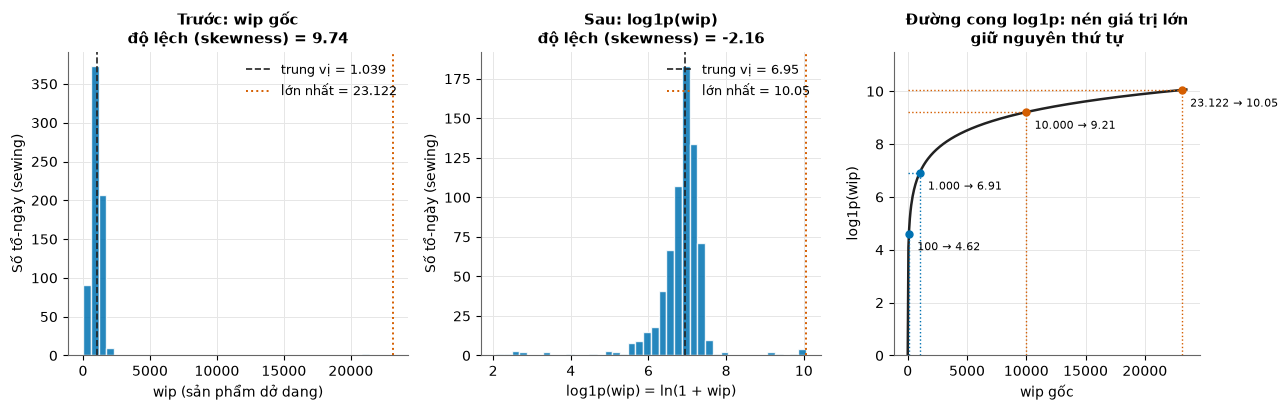

In [6]:
fig = P.plot_wip_log1p(df); plt.show()

**Nhận xét (`wip` của sewing trước và sau `log1p`).**
- **Trước:** gần như toàn bộ tổ-ngày dồn vào một cột hẹp quanh 1.000, trong khi giá trị lớn nhất là 23.122, cách xa gấp 22 lần trung vị. Độ lệch 9,74 cho thấy đuôi phải rất dài.
- **Sau:** phân bố của `log1p(wip)` có dạng hình chuông quanh 6,95, thấy rõ phần thân. Giá trị lớn nhất chỉ còn cách trung vị khoảng 3 đơn vị.
- **Đường cong bên phải:** `log1p` làm giá trị nhỏ và vừa tách xa nhau hơn, còn giá trị lớn bị nén lại: 1.000 → 6,91; 10.000 → 9,21; 23.122 → 10,05. Thứ tự giữa các tổ-ngày được giữ nguyên.
- **Lưu ý:** độ lệch chuyển từ +9,74 sang −2,16, tức là còn một nhóm ít giá trị rất nhỏ (khoảng 7–30) tạo đuôi trái nhẹ. `log1p` không loại hẳn các giá trị bất thường, chỉ làm chúng bớt chi phối.

## 5. Các vấn đề chất lượng dữ liệu (đo lại bằng số liệu thật)

In [7]:
eda.quality_checks(raw, df)

,van_de,do_duoc
0,Nhãn department lỗi,"Giá trị thô: {'sweing': 691, 'finishing ': 257, 'finishing': 249}"
1,wip thiếu có cấu trúc,"506 dòng (42.3%); thiếu ở finishing: 100%, ở sewing: 0%"
2,wip lệch phải,max = 23122; trung vị = 1039; độ lệch = 9.74
3,actual_productivity > 1,37 dòng; max = 1.120
4,"targeted_productivity < 0,5","30 dòng; giá trị: [0.07, 0.35, 0.4]; tỷ lệ miss ở nhóm này = 0.133"
5,no_of_workers không nguyên,140 dòng
6,quarter thực chất là tuần trong tháng,"{'Quarter1': 360, 'Quarter2': 335, 'Quarter3': 210, 'Quarter4': 248, 'Quarte..."
7,idle_time/idle_men gần như hằng số,idle_time>0: 18 dòng; idle_men>0: 18 dòng
8,Tổ-ngày bị thiếu,1197 dòng so với kỳ vọng 1416 (24 cặp tổ-bộ phận x 59 ngày); số dòng mỗi ngà...
9,Phạm vi thời gian,2015-01-01 đến 2015-03-11; 59 ngày làm việc; ngày trong tuần có dữ liệu: ['M...


**Nhận xét (các vấn đề chất lượng dữ liệu).**
- **Nhãn `department` lỗi:** nếu không sửa, one-hot sẽ tạo 3 bộ phận và finishing bị tách làm hai nhóm (257 + 249 dòng).
- **`wip` thiếu có cấu trúc:** thiếu theo bộ phận, không ngẫu nhiên: finishing không giữ bán thành phẩm vì nhận hàng từ sewing. Điền 0 đúng nghĩa vật lý; điền trung vị sẽ gán WIP của sewing (khoảng 1.039) cho finishing, tạo thông tin giả.
- **`wip` lệch phải:** lệch mạnh, nên dùng `log1p`.
- **Năng suất > 1:** 37 dòng năng suất > 1 (25 sewing, 12 finishing): tổ làm nhanh hơn thời gian chuẩn, có thể do `smv` đặt rộng. Giữ nguyên; các dòng này có nhãn `miss = 0`.
- **Định mức < 0,5:** 30 dòng định mức < 0,5 chỉ trượt 13,3% (so với 26,9% chung): định mức thấp thì dễ đạt. Bài có chạy lại mô hình khi loại các dòng này để kiểm tra độ nhạy.
- **Số công nhân không nguyên:** 140 dòng số công nhân lẻ (ví dụ 30,5), có thể do bán thời gian hoặc chia ca. Coi là biến liên tục.
- **`quarter` là tuần trong tháng:** đã thay bằng `week_of_month`.
- **`idle_*` gần như hằng số:** `idle_*` gần như hằng (chỉ 18 dòng khác 0) và lại phát sinh trong ngày, nên loại hẳn.
- **Tổ-ngày bị thiếu:** thiếu 219 tổ-ngày (15,5% so với kỳ vọng); xem ô dưới.
- **Phạm vi thời gian:** 59 ngày làm việc từ 01/01 đến 11/03/2015, **không có thứ Sáu** (ngày nghỉ cuối tuần ở Bangladesh).
- Không có dòng trùng hoàn toàn hay khoá (ngày, tổ, bộ phận) bị trùng.

### Tổ-ngày bị thiếu: số dòng theo ngày
Kỳ vọng 24 dòng/ngày (12 tổ × 2 bộ phận). Ngày nào thiếu thì đặc trưng trễ dùng *ngày làm việc trước của chính cặp đó*, không phải 'hôm qua'.

In [8]:
rpd = eda.rows_per_day(df)
print(rpd["n_dong"].value_counts().sort_index().to_string())
rpd.head()

n_dong
15     1
17     1
18     3
19    20
20     6
21    13
22     9
23     4
24     2


,date,n_dong,n_cap_thieu,thu
0,2015-01-01,19,5,Thursday
1,2015-01-03,21,3,Saturday
2,2015-01-04,21,3,Sunday
3,2015-01-05,22,2,Monday
4,2015-01-06,21,3,Tuesday


**Nhận xét (số dòng theo ngày).**
- Chỉ 2/59 ngày có đủ 24 dòng. Phổ biến nhất là 19 dòng/ngày (20 ngày); ít nhất là 15 dòng (20/01/2015, thiếu 9 cặp).
- Mỗi cặp (tổ, bộ phận) có từ 29 đến 59 ngày dữ liệu (trung vị 54), nên có cặp vắng gần nửa thời gian.
- Dữ liệu không cho biết lý do thiếu (tổ nghỉ, không có đơn, hay quên ghi). Nếu tổ vắng mặt vì đang gặp vấn đề thì mẫu bị thiên lệch. Nên ghi vào phần giới hạn.
- Hệ quả kỹ thuật: `lag1_*` là ngày làm việc trước **của chính cặp đó**, có thể cách nhiều ngày lịch, chứ không nhất thiết là "hôm qua".

## 6. Phân bố nhãn `miss`

In [9]:
eda.target_distribution(df, train, test)

,nhom,n_dong,n_miss,ty_le_miss
0,Toàn bộ,1197,322,0.269006
1,Train,943,254,0.269353
2,Test,254,68,0.267717
3,Bộ phận = finishing,506,204,0.403162
4,Bộ phận = sewing,691,118,0.170767
5,Tuần trong tháng = 1,360,91,0.252778
6,Tuần trong tháng = 2,335,83,0.247761
7,Tuần trong tháng = 3,210,71,0.338095
8,Tuần trong tháng = 4,248,70,0.282258
9,Tuần trong tháng = 5,44,7,0.159091


**Nhận xét (phân bố nhãn).**
- 26,9% tổ-ngày trượt định mức: mất cân bằng vừa phải. Một mô hình luôn đoán "đạt" có accuracy 73% nhưng không giúp được gì, nên dùng PR-AUC và Recall/Precision tại k cảnh báo thay cho accuracy.
- Train (26,9%) và test (26,8%) có tỷ lệ gần như bằng nhau, dù bên trong có biến động theo thời gian (hình 5).
- **Finishing trượt 40,3%, gấp 2,4 lần sewing (17,1%)**, nên `department` là tín hiệu mạnh nhất. Đây là lý do có baseline B2 "cảnh báo mọi tổ finishing".
- Theo tuần trong tháng không có quy luật rõ: tuần 3 cao nhất (33,8%); tuần 5 thấp (15,9%) nhưng chỉ có 44 dòng nên không đáng tin.
- Theo tổ, tỷ lệ dao động từ 11,6% (tổ 3) đến 45,0% (tổ 8), nên `team` có thông tin. Tuy vậy mỗi tổ chỉ khoảng 100 dòng, cần dè dặt.

### Quán tính: lần trước trượt thì lần này có dễ trượt hơn không?

In [10]:
df.groupby("lag1_miss", dropna=False)["miss"].agg(n_dong="count", ty_le_miss="mean")

,n_dong,ty_le_miss
lag1_miss,,
0.0,857,0.178530
1.0,316,0.506329
NaN,24,0.375000


**Nhận xét (quán tính trượt).**
- Khi lần làm việc trước đó tổ đã trượt, lần này trượt tới khoảng **51%**; nếu lần trước đạt thì chỉ khoảng **18%**. Dòng `NaN` là ngày đầu của cặp, chưa có lịch sử.
- Đây là "quán tính hiệu suất": vấn đề của một tổ (mã hàng khó, thiếu người, thiếu đầu vào) thường kéo dài sang ngày sau. Đó là cơ sở của baseline B1 "hôm qua trượt thì hôm nay cảnh báo" và các đặc trưng `lag1_*`, `roll5_*`.
- Mô hình chỉ có giá trị nếu làm tốt hơn quy tắc đơn giản này, vì quản đốc vốn đã làm theo kinh nghiệm như vậy.

## 7. Thiệt hại mỗi lần trượt
Thiệt hại = (targeted − actual) × số công nhân × 480 phút chuẩn; tính trên các dòng `miss = 1`.

In [11]:
eda.damage_summary(df)

,nhom,chi_tieu,n_lan_truot,trung_binh,trung_vi,p25,p75,p90,max
0,Tất cả,Thiệt hại (phút chuẩn),322,2170.647015,993.039999,456.727273,2294.073331,6683.003637,14183.957981
1,Tất cả,Sản phẩm thiếu (cái),322,205.156615,163.117978,87.783133,302.584558,418.207763,1070.939758
2,finishing,Thiệt hại (phút chuẩn),204,805.747065,617.727274,414.509090,1144.200000,1641.676363,4444.399997
3,finishing,Sản phẩm thiếu (cái),204,223.117186,177.492164,98.758621,312.173414,452.899225,1070.939758
4,sewing,Thiệt hại (phút chuẩn),118,4530.304554,3722.207994,1770.770009,6975.475481,9956.695991,14183.957981
5,sewing,Sản phẩm thiếu (cái),118,174.106136,143.190272,68.353775,285.661707,373.985612,527.512195


**Nhận xét (thiệt hại mỗi lần trượt).**
- Một lần trượt mất trung vị khoảng 993 phút chuẩn, tương đương 163 sản phẩm. Phân bố lệch phải (trung bình 2.171 > trung vị; p90 = 6.683), nên các lần trượt nặng chiếm tỷ trọng lớn: 10% lần trượt nặng nhất chiếm 43% tổng thiệt hại theo phút chuẩn (và 26% theo sản phẩm).
- **Theo phút chuẩn, sewing mất gấp 5,6 lần finishing** (4.530 so với 806 phút/lần), vì tổ sewing đông hơn nhiều (trung vị 57 người so với 8) và `smv` lớn hơn (22,5 so với 3,9 phút/sản phẩm).
- **Theo số sản phẩm thiếu thì gần tương đương** (174 so với 223 cái/lần), finishing còn nhỉnh hơn.
- Hệ quả: đơn vị đo quyết định tổ nào đáng ưu tiên. Theo phút thì nên dồn hỗ trợ cho sewing; theo sản phẩm (gần với mục tiêu giao hàng) thì finishing cũng quan trọng không kém. Đây là lý do có hai lăng kính chi phí, với lăng kính sản phẩm là chính.
- Công thức giả định ca 480 phút và chưa tính tăng ca, nên chỉ là ước lượng bậc độ lớn.

## 8. Các hình minh hoạ

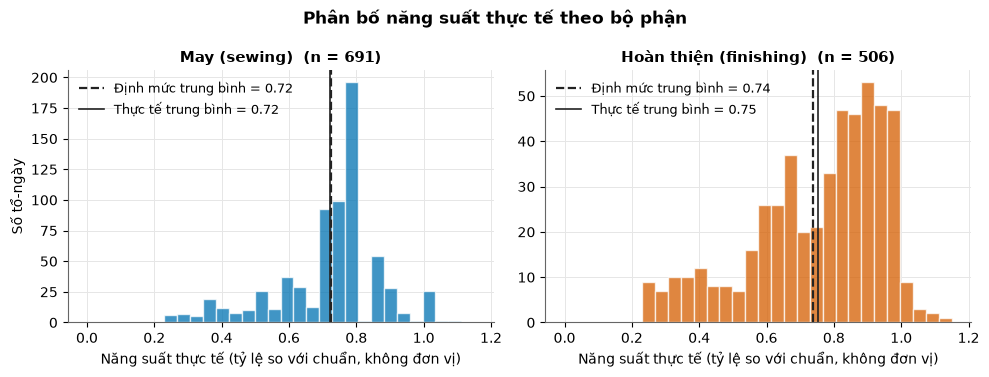

In [12]:
fig = P.plot_productivity_distribution(df); plt.show()

**Nhận xét (hình 1: phân bố năng suất).**
- **Sewing có các cột cao vọt đúng tại 0,75 và 0,8**, trùng các mức định mức phổ biến: 58% dòng sewing có |actual − targeted| < 0,001. Có thể số liệu sewing được ghi hoặc làm tròn theo định mức, hoặc tổ làm vừa đủ chỉ tiêu rồi dừng.
- Hệ quả: nhãn sewing rất nhạy với chênh lệch nhỏ. Có 17 lần trượt ở sewing chỉ hụt dưới 0,01 so với định mức, khó phân biệt với nhiễu ghi chép.
- **Finishing phân bố rộng và lệch trái**, đuôi dài xuống tới 0,23. Trung bình thực tế (0,75) xấp xỉ định mức (0,74) nhưng phương sai lớn, nên tỷ lệ trượt cao hơn hẳn sewing dù trung bình như nhau.
- Có một nhóm nhỏ năng suất > 1 ở cả hai bộ phận (năng suất > 1).

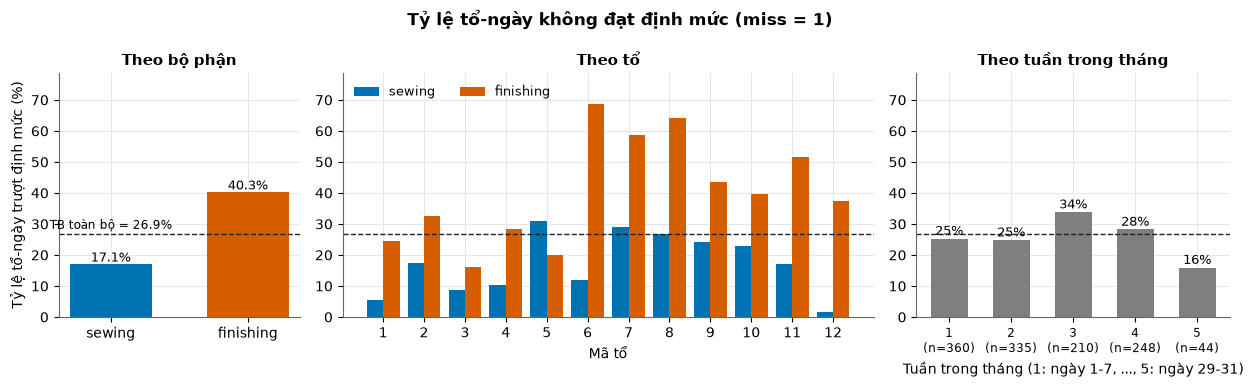

In [13]:
fig = P.plot_miss_rates(df); plt.show()

**Nhận xét (hình 2: tỷ lệ trượt).**
- Ở **mọi tổ trừ tổ 5**, finishing trượt nhiều hơn sewing. Finishing của các tổ 6, 8, 7 trượt 59–69%, trong khi sewing của tổ 12 và tổ 1 gần như không trượt (2% và 5%).
- Tổ 5 ngược chiều: sewing 31% so với finishing 20%. Như vậy rủi ro phụ thuộc vào **tổ hợp tổ × bộ phận** chứ không cộng dồn đơn giản. Đây là kiểu tương tác mà cây và Random Forest bắt tốt hơn mô hình tuyến tính.
- Theo tuần trong tháng không có xu hướng đơn điệu, nên `week_of_month` khó là biến mạnh.

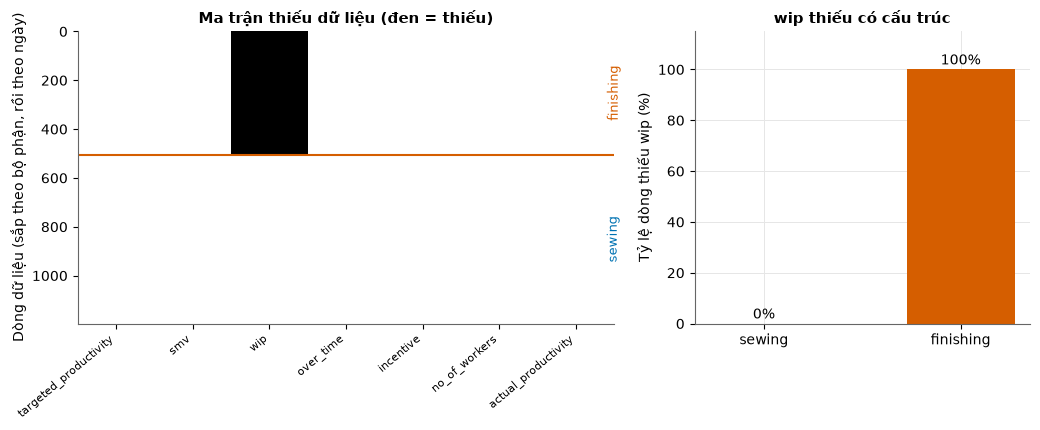

In [14]:
fig = P.plot_wip_missing(df); plt.show()

**Nhận xét (hình 3: ma trận thiếu).**
- Ma trận chỉ có **một khối đen duy nhất**, ở cột `wip` và đúng bằng phần finishing; các cột khác đầy đủ. Thiếu hoàn toàn theo bộ phận: 100% ở finishing, 0% ở sewing.
- Vì vậy cờ "wip bị thiếu" sẽ trùng 100% với `department = finishing`, không thêm thông tin mà còn làm khó diễn giải hệ số. Đó là lý do bài không tạo thêm cờ `wip_missing`.

#### Xử lý `wip` thiếu: điền 0 rồi chuẩn hoá (so sánh khi có và không có `log1p`)
`wip` thiếu hoàn toàn ở finishing nên Pipeline điền 0, sau đó `log1p`, rồi chuẩn hoá bằng trung bình và độ lệch chuẩn của train. Hình dưới là giá trị mà mô hình thực sự nhận, so sánh khi bỏ và khi giữ bước `log1p`.

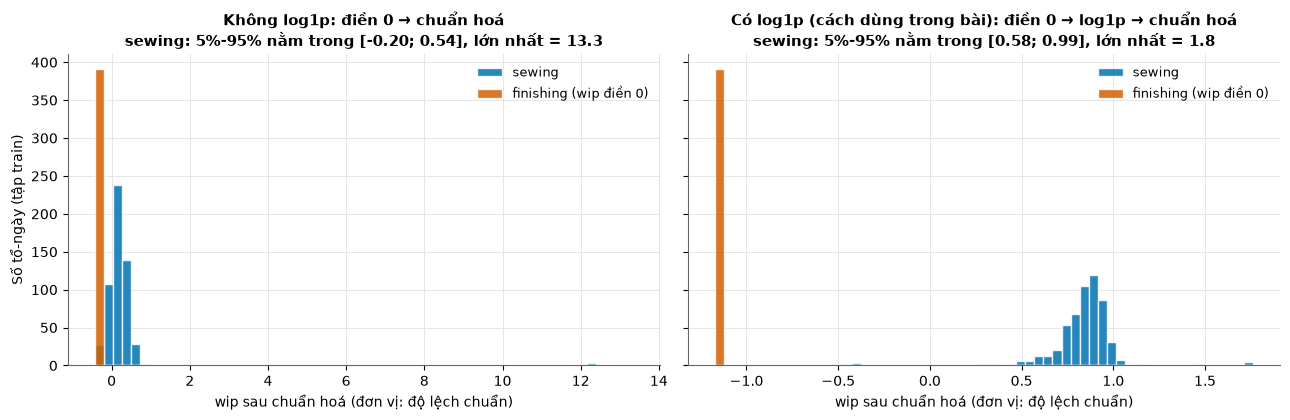

In [15]:
fig = P.plot_wip_pipeline(train); plt.show()

**Nhận xét (`wip` mà mô hình thực sự nhận, sau khi chuẩn hoá).**
- Hình vẽ trên tập **train**, dùng trung bình và độ lệch chuẩn của train (đúng như Pipeline làm), gồm cả dòng finishing đã được điền 0.
- **Không `log1p` (trái):** 90% sewing bị nén vào đoạn rất hẹp [−0,20; 0,54], trong khi một vài tổ-ngày có `wip` rất lớn đạt tới +13,3 độ lệch chuẩn. Mô hình dựa vào khoảng cách hoặc hệ số (Logistic, SVM, MLP) sẽ bị vài điểm này chi phối.
- **Có `log1p` (phải):** phần sewing trải ra thành phân bố dễ đọc, điểm xa nhất chỉ còn +1,8 độ lệch chuẩn.
- **Một tác dụng phụ cần biết:** `log1p(0) = 0` nằm rất xa `log1p(wip)` của sewing (khoảng 7), nên sau chuẩn hoá finishing bị tách hẳn khỏi sewing (cột cam bên trái hoàn toàn). Vì vậy `wip` vừa mang thông tin "bộ phận nào" vừa mang thông tin mức đệm bán thành phẩm trong sewing. Điều này giải thích vì sao khi diễn giải mô hình, hệ số hoặc độ quan trọng của `wip` không nên đọc tách khỏi `department`.
- Cây quyết định và Random Forest không phụ thuộc vào biến đổi này (chỉ quan tâm thứ tự), nhưng vẫn dùng chung pipeline.

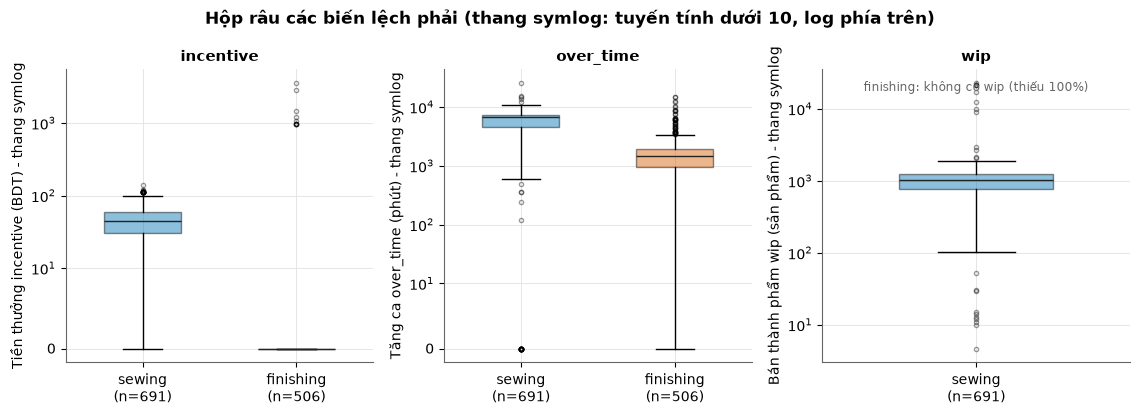

In [16]:
fig = P.plot_boxplots(df); plt.show()

**Nhận xét (hình 4: hộp râu).**
- **`incentive`:** sewing tập trung ở khoảng 30–60 BDT; finishing gần như toàn 0, chỉ có 10 dòng được thưởng, từ 960 đến 3.600 BDT, cao gấp 20 đến 80 lần mức thưởng điển hình của sewing. Biến này gần như mã hoá lại bộ phận, cộng thêm vài giá trị bất thường.
- **`over_time`:** trung vị của sewing (6.840 phút) gấp khoảng 4,8 lần finishing (1.440 phút), chủ yếu vì tổ sewing đông người (đây là tổng phút của cả tổ).
- **`wip`:** có vài giá trị rất lớn (> 10.000) và rất nhỏ (< 50), nên dùng log1p.
- Nhiều biến gắn chặt với `department` (`wip`, `incentive`, `over_time`, `no_of_workers`, `smv`), nên khi diễn giải mô hình không nên đọc tác động của từng biến riêng lẻ.

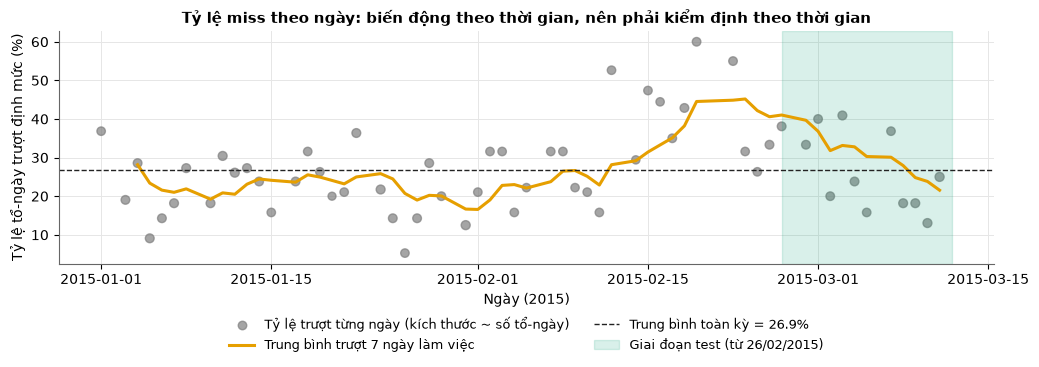

In [17]:
fig = P.plot_miss_timeseries(df, TEST_START); plt.show()

**Nhận xét (hình 5: chuỗi thời gian).**
- Tháng 1 tỷ lệ trượt ổn định quanh 20–25%. Từ khoảng 10/02 tỷ lệ tăng mạnh, đỉnh 60% trong một ngày quanh 20/02, đường trung bình 7 ngày lên khoảng 45%. Sau đó tỷ lệ giảm dần trong giai đoạn test, về khoảng 20%.
- Dữ liệu **không dừng**: k-fold ngẫu nhiên sẽ dùng thông tin của tương lai để dự báo quá khứ, nên phải kiểm định theo thời gian (rolling-origin).
- Tập test (12 ngày) bắt đầu ngay sau đỉnh, khi tỷ lệ đang giảm, nên điều kiện test khác phần lớn giai đoạn train. Fold CV cuối (17–25/02) lại rơi đúng đỉnh. Đây là một lý do khiến điểm số dao động mạnh giữa các fold và giữa CV với test.

## 9. Tổng kết EDA và hệ quả cho các bước sau

| Phát hiện | Hệ quả / quyết định |
|---|---|
| 1.197 tổ-ngày, 59 ngày, 1 nhà máy; thiếu 15,5% tổ-ngày | Dữ liệu nhỏ: dùng lưới siêu tham số nhỏ, ưu tiên mô hình đơn giản, kết luận dè dặt |
| Tỷ lệ trượt 26,9% | Không dùng accuracy; chọn mô hình bằng PR-AUC, đánh giá tại k = 3 cảnh báo/ngày |
| Finishing trượt 40% so với sewing 17%; tương tác tổ × bộ phận | `department`, `team` là biến phân loại; baseline B2 |
| Trượt có quán tính (51% so với 18%) | Đặc trưng trễ theo cặp tổ-bộ phận; baseline B1 |
| `wip` thiếu 100% ở finishing, lệch phải | Điền 0, log1p, chuẩn hoá trong Pipeline; không cần cờ thiếu |
| `idle_*` phát sinh trong ngày; `incentive`, `over_time` không rõ thời điểm | Loại `idle_*`; kịch bản A bỏ thêm `incentive`, `over_time`, `no_of_style_change`, kịch bản B giữ để đo độ nhạy |
| `quarter` là tuần trong tháng | Thay bằng `week_of_month` |
| Định mức < 0,5 ít trượt | Giữ trong dữ liệu chính, kiểm tra độ nhạy |
| Thiệt hại theo phút lệch về sewing, theo sản phẩm thì tương đương | Hai lăng kính chi phí, lăng kính sản phẩm là chính |
| Tỷ lệ trượt biến động theo thời gian | Tách test theo ngày, CV rolling-origin |
| Sewing dồn đúng định mức; 17 dòng trùng giữa các tổ; ngày thiếu không rõ lý do | Ghi vào phần giới hạn của báo cáo |